In [1]:
#导入实验相关依赖库
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

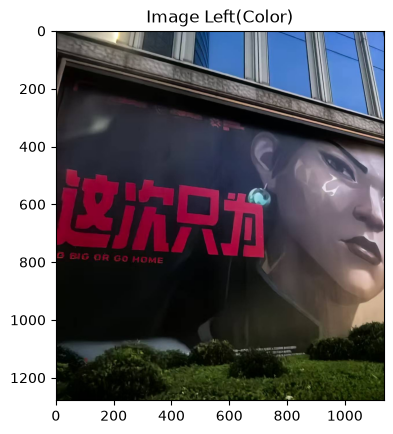

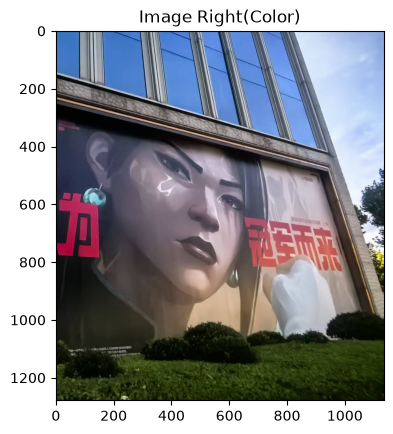

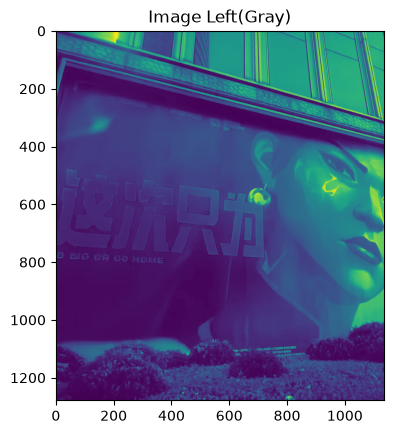

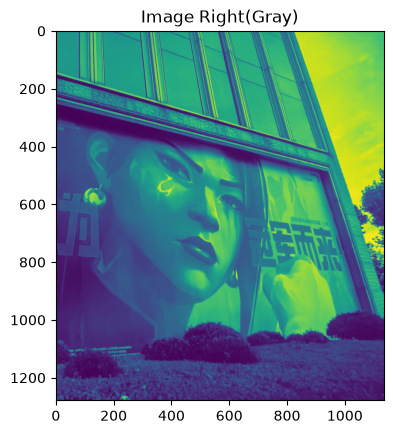

In [2]:
# 读取图像
img_a = cv2.cvtColor(cv2.imread("img/left.jpg"), cv2.COLOR_BGR2RGB)
plt.imshow(img_a)
plt.title('Image Left(Color)')
plt.savefig('result/original_left.jpg')
plt.show()

img_b = cv2.cvtColor(cv2.imread("img/right.jpg"), cv2.COLOR_BGR2RGB)
plt.imshow(img_b)
plt.title('Image Right(Color)')
plt.savefig('result/original_right.jpg')
plt.show()

# 将图像转换为灰度图
gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_a)
plt.title('Image Left(Gray)')
plt.savefig('result/gray_left.jpg')
plt.show()

gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_b)
plt.title('Image Right(Gray)')
plt.savefig('result/gray_right.jpg')
plt.show()

In [3]:
# 创建SIFT特征检测器
sift = cv2.SIFT_create()

# 检测关键点并计算描述子
kp_a, des_a = sift.detectAndCompute(img_a, None)
kp_b, des_b = sift.detectAndCompute(img_b, None)

# 使用FLANN进行特征匹配
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)# 检查次数越多，匹配越准确但速度越慢

flann = cv2.FlannBasedMatcher(index_params, search_params)

matches = flann.knnMatch(des_a, des_b, k=2)# k=2表示每个特征点返回2个最佳匹配

# Lowe's 比率测试(筛选优质匹配点)
good_matches = []

for m, n in matches:
    if m.distance < 0.7 * n.distance:# 比率阈值通常取0.7-0.8
        good_matches.append(m)

# 输出匹配统计信息
print("=== 特征匹配统计 ===")
print(f"初始匹配点对数: {len(matches)}")
print(f"筛选后优质匹配点对数: {len(good_matches)}")
print(f"过滤掉的匹配点对数: {len(matches) - len(good_matches)}")
print(f"优质匹配点比例: {len(good_matches)/len(matches):.2%}")

=== 特征匹配统计 ===
初始匹配点对数: 1944
筛选后优质匹配点对数: 979
过滤掉的匹配点对数: 965
优质匹配点比例: 50.36%


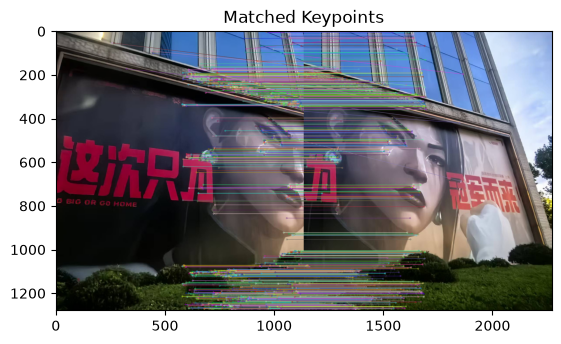

In [4]:
# 绘制匹配的SIFT关键点
matched_keypoints_img = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b, good_matches,
    None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.imshow(matched_keypoints_img)
plt.title('Matched Keypoints')
plt.savefig('result/Matched Keypoints.jpg')
plt.show()

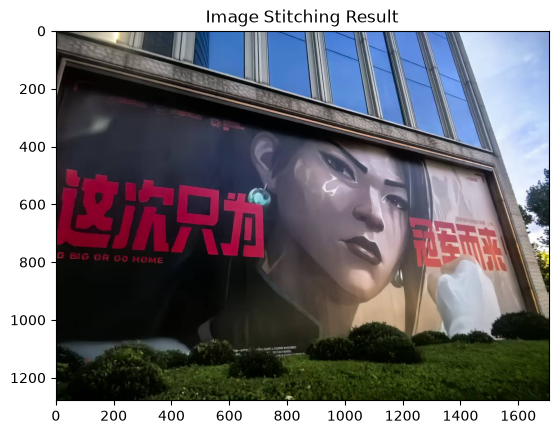

In [9]:
# 提取匹配点的坐标
src_pts = np.float32([kp_b[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp_a[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

# 使用RANSAC算法估计单应矩阵
H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

# 获取输入图像尺寸
h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

# 计算图像变换后的四个角坐标
pts = np.float32([[0, 0], [0, h_b], [w_b, h_b], [w_b, 0]]).reshape(-1, 1, 2)
dst_corners = cv2.perspectiveTransform(pts, H)

# 确定拼接后图像的最终尺寸
all_corners = np.concatenate([dst_corners, np.float32([[0,0], [w_a,0], [w_a,h_a], [0,h_a]]).reshape(-1,1,2)], axis=0)
[x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() + 0.5)
[x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

# 创建平移矩阵，确保所有像素都在可视区域内
translation_matrix = np.array([[1, 0, -x_min], [0, 1, -y_min], [0, 0, 1]], dtype=np.float32)

# 对图像进行透视变换和平移
fus_img = cv2.warpPerspective(
    img_b,
    translation_matrix @ H, 
    (x_max - x_min, y_max - y_min)
)

# 将图像复制到拼接结果的对应位置
fus_img[-y_min : h_a - y_min, -x_min : w_a - x_min] = img_a

plt.imshow(fus_img)
plt.title('Image Stitching Result')
plt.savefig('result/Image Stitching Result.jpg', dpi=300, bbox_inches='tight')
plt.show()